In [46]:
import urllib.request
import zipfile
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,ConfusionMatrixDisplay)

In [47]:
np.random.seed(42)
tf.random.set_seed(42)

#Configurations
pd.set_option('display.float_format',lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)



In [48]:
# step 1 - download the daatset zip file
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
urllib.request.urlretrieve(url, "dataset.zip")

#unziping it
with zipfile.ZipFile("dataset.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("dataset is ready")

dataset is ready


In [49]:
#load the training dataset

X_train_full = pd.read_csv("/content/UCI HAR Dataset/train/X_train.txt", sep=r"\s+", header=None)
y_train_full = pd.read_csv("/content/UCI HAR Dataset/train/y_train.txt", sep=r"\s+", header=None)
#/content/UCI HAR Dataset/train/X_train.txt
X_test_raw = pd.read_csv("/content/UCI HAR Dataset/test/X_test.txt", sep=r"\s+", header=None)
y_test = pd.read_csv("/content/UCI HAR Dataset/test/y_test.txt", sep=r"\s+", header=None)

#Subject data
subjects = pd.read_csv("/content/UCI HAR Dataset/train/subject_train.txt",sep=r"\s+",header=None)

In [50]:
X_train_full.shape, y_train_full.shape, X_test_raw.shape, y_test.shape


((7352, 561), (7352, 1), (2947, 561), (2947, 1))

In [51]:
X_train_full.head()

,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
0,0.289,-0.020,-0.133,-0.995,-0.983,-0.914,-0.995,-0.983,-0.924,-0.935,...,-0.074,-0.299,-0.710,-0.113,0.030,-0.465,-0.018,-0.841,0.180,-0.059
1,0.278,-0.016,-0.124,-0.998,-0.975,-0.960,-0.999,-0.975,-0.958,-0.943,...,0.158,-0.595,-0.861,0.053,-0.007,-0.733,0.704,-0.845,0.180,-0.054
2,0.280,-0.019,-0.113,-0.995,-0.967,-0.979,-0.997,-0.964,-0.977,-0.939,...,0.415,-0.391,-0.760,-0.119,0.178,0.101,0.809,-0.849,0.181,-0.049
3,0.279,-0.026,-0.123,-0.996,-0.983,-0.991,-0.997,-0.983,-0.989,-0.939,...,0.405,-0.117,-0.483,-0.037,-0.013,0.640,-0.485,-0.849,0.182,-0.048
4,0.277,-0.017,-0.115,-0.998,-0.981,-0.990,-0.998,-0.980,-0.990,-0.942,...,0.088,-0.351,-0.699,0.123,0.123,0.694,-0.616,-0.848,0.185,-0.044


In [52]:
#Quick analysis

print(X_train_full.shape)
print(y_train_full.shape)
y_train_full.value_counts()

(7352, 561)
(7352, 1)


,count
0,
6,1407
5,1374
4,1286
1,1226
2,1073
3,986


In [53]:
#flatten label to one dimension and shofting to 0-5 instead of 1-6
y_train_full = np.asarray(y_train_full).ravel()
y_test = np.asarray(y_test).ravel()

y_train_full = y_train_full - 1
y_test = y_test - 1

print("unique ladels after shift", np.unique(y_train_full))
print("unique ladels after shift", np.unique(y_test))


unique ladels after shift [0 1 2 3 4 5]
unique ladels after shift [0 1 2 3 4 5]


In [54]:
CLASS_NAMES = ["Walking", "Walking Up", "Walking Down", "Sitting", "Standing", "Laying"]
N_CLASSES = len(CLASS_NAMES)

print(CLASS_NAMES)
print(N_CLASSES)

['Walking', 'Walking Up', 'Walking Down', 'Sitting', 'Standing', 'Laying']
6


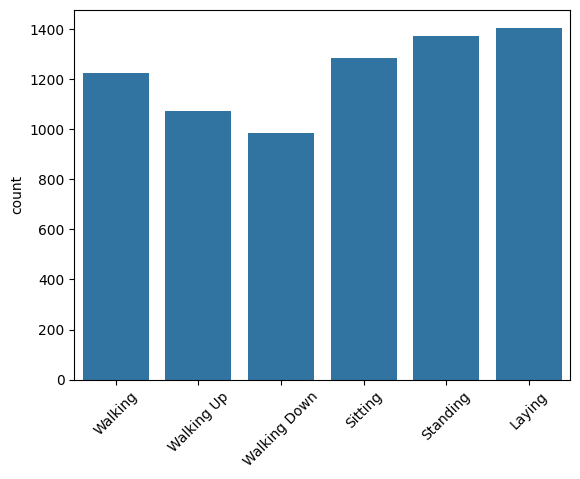

In [55]:
sns.countplot(x=y_train_full)
plt.xticks(ticks=np.arange(N_CLASSES), labels=CLASS_NAMES,rotation=45)
plt.show()

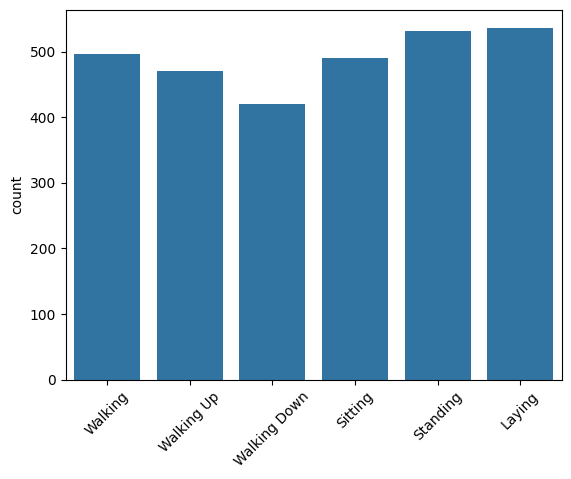

In [56]:
sns.countplot(x=y_test)
plt.xticks(ticks=np.arange(N_CLASSES), labels=CLASS_NAMES,rotation=45)
plt.show()

In [57]:
#Splitting the data

# split using GSS
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, val_idx = next(gss.split(X_train_full, y_train_full, groups=subjects))

X_train, X_val = X_train_full.iloc[train_idx], X_train_full.iloc[val_idx]
y_train, y_val = y_train_full[train_idx], y_train_full[val_idx]

print("Train:", X_train.shape, "  labels:", y_train.shape)
print("Val:  ", X_val.shape,   "  labels:", y_val.shape)
print("Test: ", X_test_raw.shape, "  labels:", y_test.shape)


Train: (5551, 561)   labels: (5551,)
Val:   (1801, 561)   labels: (1801,)
Test:  (2947, 561)   labels: (2947,)


In [58]:
print(
    "Subjects in both sets:",
    set(subjects.iloc[train_idx]) & set(subjects.iloc[val_idx])
)

Subjects in both sets: {0}


In [59]:
#Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_raw = scaler.transform(X_test_raw)

In [60]:
#Building the neural network
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(256,activation="relu",kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(128,activation="relu",kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(N_CLASSES,activation="softmax")
])


In [61]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       143,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,542 (693.52 KB)

 Trainable params: 177,542 (693.52 KB)

 Non-trainable params: 0 (0.00 B)

In [88]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss = keras.losses.SparseCategoricalCrossentropy(),
    metrics = ["accuracy"]
)

In [89]:
early_stopping = keras.callbacks.EarlyStopping(
    patience=10,
    monitor= "val_loss",
    restore_best_weights=True
)


In [90]:
history =model.fit(
    X_train,
    y_train,
    validation_data=(X_val,y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9760 - loss: 0.1541 - val_accuracy: 0.9417 - val_loss: 0.2617
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9834 - loss: 0.1400 - val_accuracy: 0.9572 - val_loss: 0.2226
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9845 - loss: 0.1242 - val_accuracy: 0.9511 - val_loss: 0.2453
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9883 - loss: 0.1180 - val_accuracy: 0.9556 - val_loss: 0.2355
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9775 - loss: 0.1419 - val_accuracy: 0.9611 - val_loss: 0.2063
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9814 - loss: 0.1387 - val_accuracy: 0.9628 - val_loss: 0.1918
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9859 - loss: 0.1309 - val_accuracy: 0.9467 - val_loss: 0.2627
Epoch 8/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9827 - loss: 0.1369 - val_accuracy: 0.95

In [91]:
print(history.history)

{'accuracy': [0.9760403633117676, 0.9834263920783997, 0.9845073223114014, 0.9882903695106506, 0.9774815440177917, 0.981444776058197, 0.9859485030174255, 0.98270583152771, 0.9877499341964722, 0.9832462668418884, 0.9850477576255798, 0.9877499341964722, 0.9873896837234497, 0.9899117350578308, 0.9888308644294739, 0.9897315502166748], 'loss': [0.15413467586040497, 0.13999924063682556, 0.1241554245352745, 0.11799188703298569, 0.14188453555107117, 0.13867126405239105, 0.13087980449199677, 0.1369047909975052, 0.11878323554992676, 0.12778687477111816, 0.12680792808532715, 0.11316139250993729, 0.10686860978603363, 0.10061799734830856, 0.09883850067853928, 0.09592011570930481], 'val_accuracy': [0.9416990280151367, 0.957245945930481, 0.9511382579803467, 0.9555802345275879, 0.9611327052116394, 0.9627984166145325, 0.9466962814331055, 0.95391446352005, 0.9594669342041016, 0.9511382579803467, 0.9533592462539673, 0.9516934752464294, 0.9339255690574646, 0.95391446352005, 0.942809522151947, 0.94114381074

In [92]:
hist = history.history

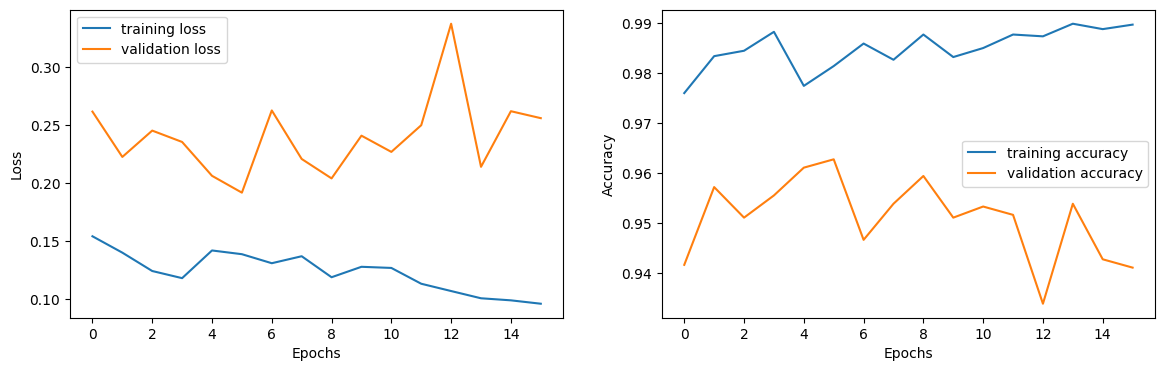

In [93]:
fig, axes = plt.subplots(1,2,figsize=(14,4))

axes[0].plot(hist["loss"],label="training loss")
axes[0].plot(hist["val_loss"],label="validation loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(hist["accuracy"],label="training accuracy")
axes[1].plot(hist["val_accuracy"],label="validation accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.show()

In [94]:
#evaluation on the test set

test_loss,test_acc = model.evaluate(X_test_raw,y_test)
print("Test accuracy:",test_acc)
print("Test loss",test_loss)

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9325 - loss: 0.3220
Test accuracy: 0.9324737191200256
Test loss 0.32195261120796204


In [95]:
#getting the predictions of the test data
y_proba = model.predict(X_test_raw,verbose=0)
y_pred = np.argmax(y_proba,axis=1)

In [96]:
y_proba[0]

array([0.00000376, 0.0000208 , 0.00000438, 0.00094772, 0.9990203 ,
       0.00000292], dtype=float32)

In [97]:
print(y_proba.shape)

(2947, 6)


In [98]:
print(y_proba[:3])

[[0.00000376 0.0000208  0.00000438 0.00094772 0.9990203  0.00000292]
 [0.00004925 0.00023019 0.00006169 0.53924114 0.4602315  0.00018621]
 [0.00004283 0.000029   0.00001231 0.00501922 0.9948815  0.00001523]]


In [99]:
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[427  11  58   0   0   0]
 [  9 449  13   0   0   0]
 [ 10  11 394   0   5   0]
 [  0   1   0 449  41   0]
 [  0   0   0  40 492   0]
 [  0   0   0   0   0 537]]


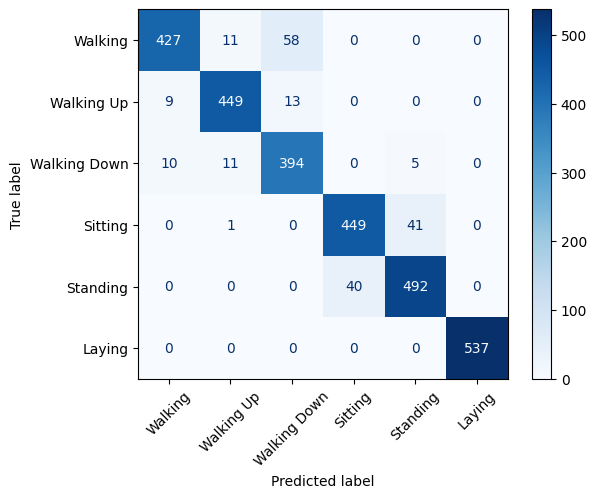

In [100]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=CLASS_NAMES)
disp.plot(cmap=plt.cm.Blues,xticks_rotation=45)
plt.show()

In [101]:
cr = classification_report(y_test,y_pred,target_names = CLASS_NAMES)

In [102]:
print(cr)

              precision    recall  f1-score   support

     Walking       0.96      0.86      0.91       496
  Walking Up       0.95      0.95      0.95       471
Walking Down       0.85      0.94      0.89       420
     Sitting       0.92      0.91      0.92       491
    Standing       0.91      0.92      0.92       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.93      0.93      0.93      2947
weighted avg       0.93      0.93      0.93      2947



In [103]:
#Saving the model
#Saving the Scaler

model.save("har_model.keras")
joblib.dump(scaler,"scaler.joblib")

print("model and the scaler saved")

model and the scaler saved


In [104]:
#loading the model again predicting on new data points
#basically this can be run on completely diffferent NoteBook

loaded_model = keras.models.load_model("har_model.keras")
loaded_scaler = joblib.load("scaler.joblib")

In [105]:
def get_prediction(input):
  input_data = np.asarray(input).reshape(1,-1)
  input_data_scaled= loaded_scaler.transform(input_data)
  prediction = loaded_model.predict(input_data_scaled)
  predicted_class = np.argmax(prediction)
  return CLASS_NAMES[predicted_class]

In [112]:
print(X_test_raw[0])

[-0.25745539 -0.21138151  2.12905496 -0.73625468 -0.79212171 -0.16762818
 -0.75338759 -0.79674928 -0.1767441  -0.77424072 -0.86233648  0.27955317
  0.52801326  0.70659575  0.65624274 -0.68572959 -0.68854815 -0.77344415
 -0.4169928  -0.77645004 -0.80079911 -0.50659052 -0.13582086 -0.53644762
  1.0873472   2.10959737 -2.3883671   2.131163   -0.7495514   0.91182977
 -0.72230594 -0.15001906  0.02562942 -0.43250226  0.19605942 -0.86768567
  0.48721124  0.49362622 -0.8506193  -2.08696126  0.53567571 -0.80285364
  0.07598239  0.49300749  0.28733832  4.06569836  0.45380099  0.29260812
  3.67859264  0.59918707 -0.77855818  0.16980844  0.53211965 -0.78687115
 -0.41055581  0.13912106  0.57363499 -0.28985375 -0.5377216   0.2439057
  0.22716695  2.15449     0.65832822 -0.478292    2.40671811  0.41077106
 -0.60005051  0.77729998 -0.93031269 -1.55352465  1.52386333 -1.4595424
  1.35468648 -2.10258677  2.09065015 -2.05206305  1.98448682  1.13350418
 -1.2824052  -1.47441246 -0.04217154  0.22898938 -0.6

In [107]:
print(y_test[0])

4


In [113]:
pred_new =get_prediction(X_test_raw[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


In [114]:
print(pred_new)

Walking Down
